In [1]:
import sounddevice as sd
import numpy as np
import soundfile as sf
from src.audio_device import AudioDevice
from src.sharc import Sharc
import matplotlib.pyplot as plt
import librosa
import mido
print(sd.query_devices())

   0 Microsoft Sound Mapper - Input, MME (2 in, 0 out)
>  1 Analogue 1 + 2 (8- Focusrite US, MME (8 in, 0 out)
   2 Microphone Array (Intel® Smart , MME (4 in, 0 out)
   3 Microsoft Sound Mapper - Output, MME (0 in, 2 out)
<  4 Realtek HD Audio 2nd output (Re, MME (0 in, 2 out)
   5 Speakers (8- Focusrite USB Audi, MME (0 in, 8 out)
   6 Speakers (Realtek(R) Audio), MME (0 in, 2 out)
   7 Primary Sound Capture Driver, Windows DirectSound (2 in, 0 out)
   8 Analogue 1 + 2 (8- Focusrite USB Audio), Windows DirectSound (8 in, 0 out)
   9 Microphone Array (Intel® Smart Sound Technology (Intel® SST)), Windows DirectSound (4 in, 0 out)
  10 Primary Sound Driver, Windows DirectSound (0 in, 2 out)
  11 Realtek HD Audio 2nd output (Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
  12 Speakers (8- Focusrite USB Audio), Windows DirectSound (0 in, 8 out)
  13 Speakers (Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
  14 Speakers (8- Focusrite USB Audio), Windows WASAPI (0 in, 2 out)
  1

In [2]:
arthur, sr = sf.read('data/arthur_clip_48k.wav')

fs = 96_000
arthur_96 = librosa.resample(arthur, orig_sr=sr, target_sr=fs)


ad = AudioDevice(fs, in_device=1, out_device=4)

In [3]:
sharc = Sharc(arthur_96, ad)


Using output: USB2.0-MIDI 2
Using input:  USB2.0-MIDI 1


In [10]:
sharc.no_cancel(1)

In [11]:
sharc.no_cancel(2)

Overall ANC / No ANC: -1.80 dB


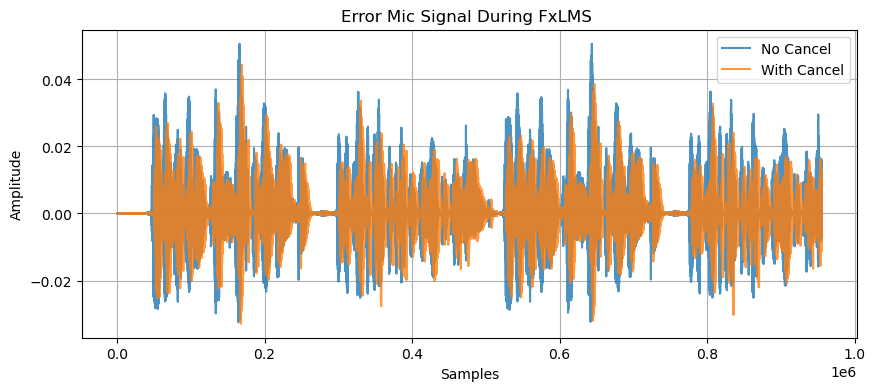

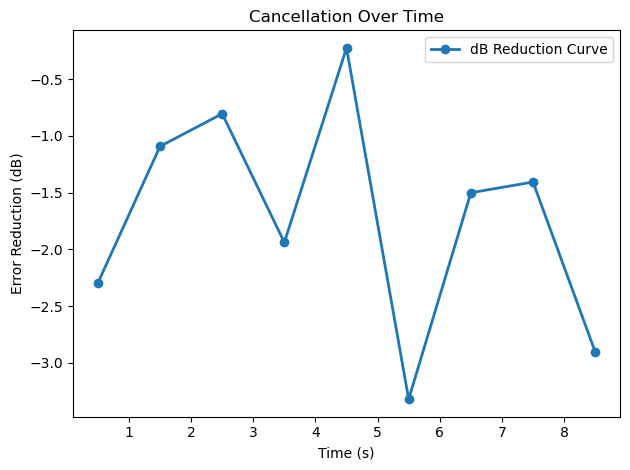

In [14]:
sharc.cancel(
    2,
    adapt=True,
    log_wnorm=False,
    mu=1e-3,
    leak=1e-7,
    lag=92,
    clean_feedback=True
)

sharc.plot_error_mic()
sharc.plot_loss_curve()

In [ ]:
lags = list(range(70, 122, 2))
db_redux = []

for lag in lags:
    print("Lag: ", lag)
    sharc.reset()
    db = sharc.cancel(
        2,
        adapt=True,
        log_wnorm=False,
        mu=1e-3,
        cancel_gain=0.15,
        leak=1e-7,
        clean_feedback=True,
        lag=lag,
    )
    db_redux.append(db)
    print()

Lag:  70
Overall ANC / No ANC: -1.09 dB

Lag:  72
Overall ANC / No ANC: -1.03 dB

Lag:  74
Overall ANC / No ANC: -1.06 dB

Lag:  76
Overall ANC / No ANC: -1.07 dB

Lag:  78
Overall ANC / No ANC: -1.08 dB

Lag:  80
Overall ANC / No ANC: -1.08 dB

Lag:  82
Overall ANC / No ANC: -1.09 dB

Lag:  84
Overall ANC / No ANC: -1.09 dB

Lag:  86
Overall ANC / No ANC: -1.08 dB

Lag:  88
Overall ANC / No ANC: -1.09 dB

Lag:  90
Overall ANC / No ANC: -1.06 dB

Lag:  92
Overall ANC / No ANC: -1.09 dB

Lag:  94
Overall ANC / No ANC: -1.09 dB

Lag:  96
Overall ANC / No ANC: -1.05 dB

Lag:  98
Overall ANC / No ANC: -1.05 dB

Lag:  100
Overall ANC / No ANC: -1.04 dB

Lag:  102
Overall ANC / No ANC: -1.01 dB

Lag:  104
Overall ANC / No ANC: -1.00 dB

Lag:  106
Overall ANC / No ANC: -0.98 dB

Lag:  108
Overall ANC / No ANC: -0.97 dB

Lag:  110
Overall ANC / No ANC: -0.93 dB

Lag:  112
Overall ANC / No ANC: -0.91 dB

Lag:  114
Overall ANC / No ANC: -0.89 dB

Lag:  116
Overall ANC / No ANC: -0.85 dB

Lag:  1

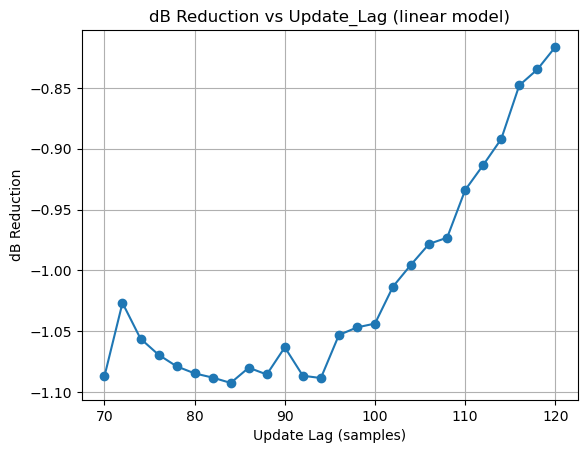

In [18]:
plt.plot(lags, db_redux, marker='o')

plt.title(f"dB Reduction vs Update_Lag (linear model)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.show()

In [19]:
lags = list(range(70, 122, 2))
db_redux = []

for lag in lags:
    print("Lag: ", lag)
    sharc.reset()
    db = sharc.cancel(
        2,
        adapt=True,
        log_wnorm=False,
        mu=1e-3,
        cancel_gain=0.15,
        leak=1e-7,
        clean_feedback=True,
        lag=lag,
    )
    db_redux.append(db)
    print()

Lag:  70
Overall ANC / No ANC: -0.66 dB

Lag:  72
Overall ANC / No ANC: -0.69 dB

Lag:  74
Overall ANC / No ANC: -0.70 dB

Lag:  76
Overall ANC / No ANC: -0.71 dB

Lag:  78
Overall ANC / No ANC: -0.69 dB

Lag:  80
Overall ANC / No ANC: -0.69 dB

Lag:  82
Overall ANC / No ANC: -0.65 dB

Lag:  84
Overall ANC / No ANC: -0.57 dB

Lag:  86
Overall ANC / No ANC: -0.49 dB

Lag:  88
Overall ANC / No ANC: -0.31 dB

Lag:  90
Overall ANC / No ANC: -0.07 dB

Lag:  92
Overall ANC / No ANC: 0.37 dB

Lag:  94


KeyboardInterrupt: 

In [ ]:
plt.plot(lags, db_redux, marker='o')

plt.title(f"dB Reduction vs Update_Lag (nonlinear model)")
plt.xlabel("Update Lag (samples)")
plt.ylabel("dB Reduction")
plt.grid(True)
plt.show()

In [37]:
sharc.no_cancel(5)

Overall ANC / No ANC: -0.91 dB


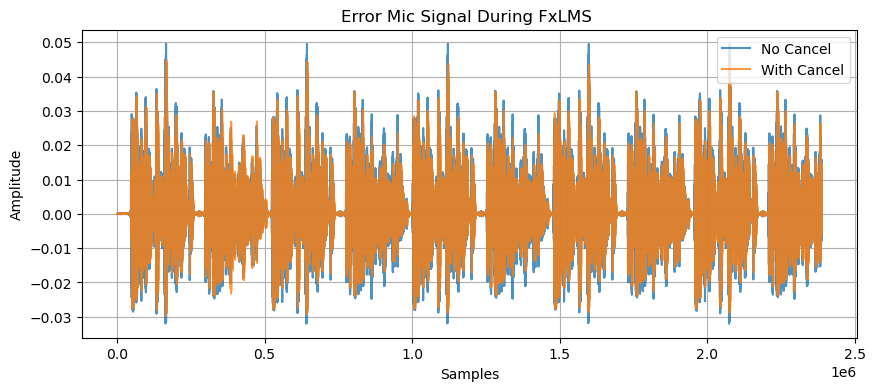

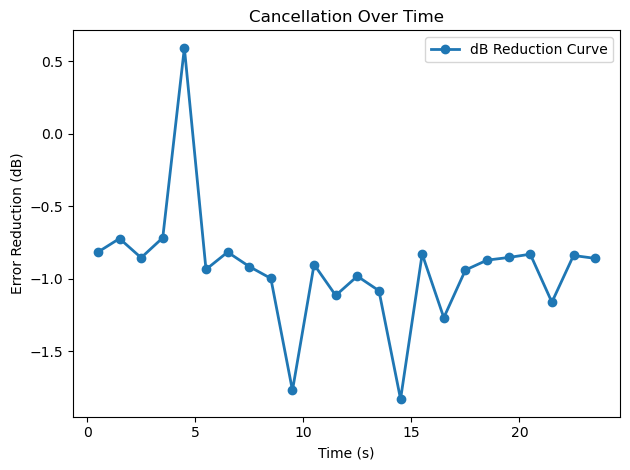

In [40]:
sharc.reset()
sharc.cancel(
    5,
    adapt=True,
    log_wnorm=False,
    mu=1e-3,
    leak=1e-7,
    cancel_gain=0.15,
    lag=84,
    clean_feedback=True
)

sharc.plot_error_mic()
sharc.plot_loss_curve()

Overall ANC / No ANC: -0.83 dB


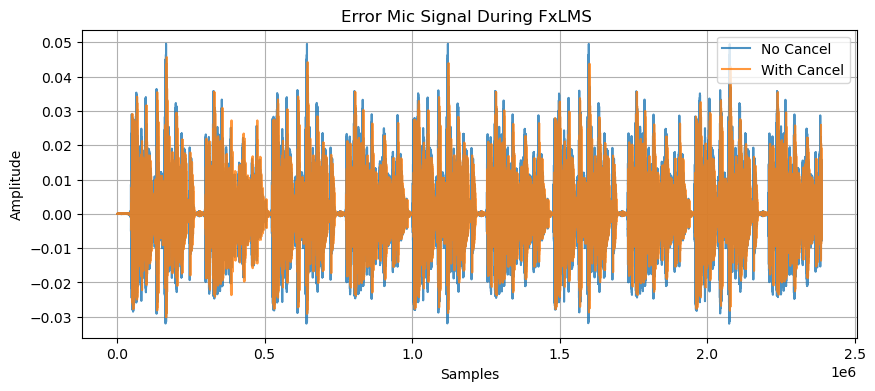

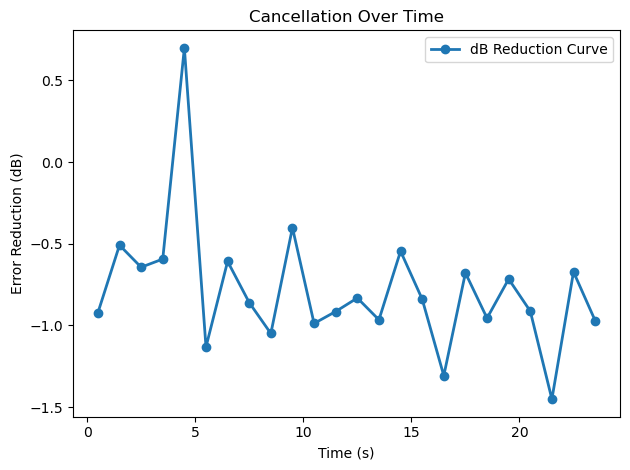

In [42]:
sharc.reset()
sharc.cancel(
    5,
    adapt=True,
    log_wnorm=False,
    mu=1e-3,
    leak=1e-7,
    cancel_gain=0.15,
    lag=84,
    clean_feedback=True
)

sharc.plot_error_mic()
sharc.plot_loss_curve()

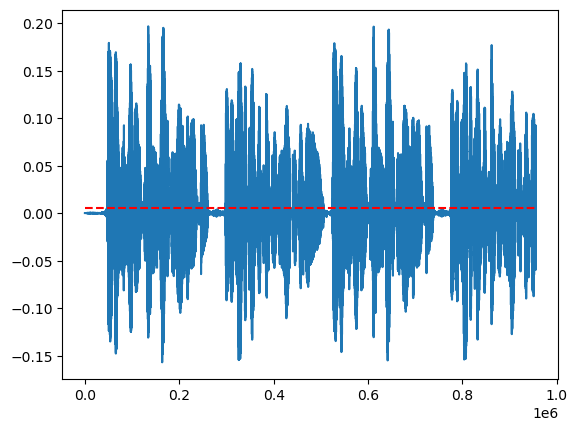

In [30]:
plt.plot(sharc.ref_log)
plt.hlines(y=.005, xmin=0, xmax=len(sharc.ref_log), colors='r', linestyles='--', label='Final Value')